In [61]:
#librerias
import pandas as pd
import numpy as np  # matrices y vectores
import matplotlib.pyplot as plt #gráfica

import warnings
warnings.simplefilter("ignore")

In [62]:
#cargar datos preparados
data = pd.read_csv("hotel_bookings_preparado.csv")
data.head()

,hotel,is_canceled,lead_time,arrival_date_month,adults,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,booking_changes,deposit_type,days_in_waiting_list,customer_type,required_car_parking_spaces,total_of_special_requests
0,Resort Hotel,0,342,July,2,PRT,Direct,Direct,0,0,0,C,3,No Deposit,0,Transient,0,0
1,Resort Hotel,0,737,July,2,PRT,Direct,Direct,0,0,0,C,4,No Deposit,0,Transient,0,0
2,Resort Hotel,0,7,July,1,GBR,Direct,Direct,0,0,0,A,0,No Deposit,0,Transient,0,0
3,Resort Hotel,0,13,July,1,GBR,Corporate,Corporate,0,0,0,A,0,No Deposit,0,Transient,0,0
4,Resort Hotel,0,14,July,2,GBR,Online TA,TA/TO,0,0,0,A,0,No Deposit,0,Transient,0,1


In [63]:

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119210 entries, 0 to 119209
Data columns (total 18 columns):
 #   Column                          Non-Null Count   Dtype 
---  ------                          --------------   ----- 
 0   hotel                           119210 non-null  object
 1   is_canceled                     119210 non-null  int64 
 2   lead_time                       119210 non-null  int64 
 3   arrival_date_month              119210 non-null  object
 4   adults                          119210 non-null  int64 
 5   country                         119210 non-null  object
 6   market_segment                  119210 non-null  object
 7   distribution_channel            119210 non-null  object
 8   is_repeated_guest               119210 non-null  int64 
 9   previous_cancellations          119210 non-null  int64 
 10  previous_bookings_not_canceled  119210 non-null  int64 
 11  reserved_room_type              119210 non-null  object
 12  booking_changes               

In [64]:
#Configuración de variables
objetivo = 'is_canceled'
predictoras_numericas = ['lead_time', 'adults', 'previous_cancellations', 'previous_bookings_not_canceled',
                         'booking_changes', 'days_in_waiting_list', 'required_car_parking_spaces', 'total_of_special_requests']
predictoras_categoricas_2cat = ['hotel', 'is_repeated_guest']
predictoras_categoricas_multicat = ['arrival_date_month', 'country', 'market_segment', 'distribution_channel',
                                    'reserved_room_type', 'deposit_type', 'customer_type']

In [65]:
#Corrección de tipos de datos
for variable in predictoras_categoricas_2cat + predictoras_categoricas_multicat:
    data[variable] = data[variable].astype(str).astype('category')
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119210 entries, 0 to 119209
Data columns (total 18 columns):
 #   Column                          Non-Null Count   Dtype   
---  ------                          --------------   -----   
 0   hotel                           119210 non-null  category
 1   is_canceled                     119210 non-null  int64   
 2   lead_time                       119210 non-null  int64   
 3   arrival_date_month              119210 non-null  category
 4   adults                          119210 non-null  int64   
 5   country                         119210 non-null  category
 6   market_segment                  119210 non-null  category
 7   distribution_channel            119210 non-null  category
 8   is_repeated_guest               119210 non-null  category
 9   previous_cancellations          119210 non-null  int64   
 10  previous_bookings_not_canceled  119210 non-null  int64   
 11  reserved_room_type              119210 non-null  category
 12  bo

<Axes: xlabel='is_canceled'>

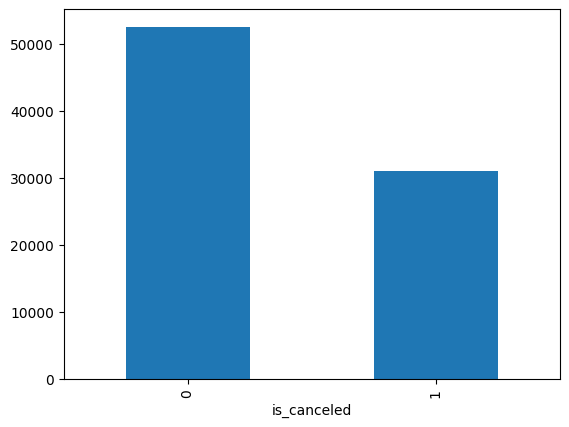

In [66]:
#División 70-30
from sklearn.model_selection import train_test_split
X = data.drop(objetivo, axis = 1) # Variables predictoras
Y = data[objetivo] #Variable objetivo
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, stratify=Y, random_state=42) #Muestreo estratificado
Y_train.value_counts().plot(kind='bar')

In [ ]:
#Creación de variables: los países con menos del 0.5% de las reservas del 70% (antes del balanceo) se agrupan en "Otros"
frecuencia = X_train['country'].value_counts(normalize=True)
paises = list(frecuencia[frecuencia >= 0.005].index)
print("Países que se conservan:", len(paises))

X_train['country'] = X_train['country'].astype(str).where(X_train['country'].astype(str).isin(paises), 'Otros').astype('category')
X_train['country'].value_counts()

In [ ]:
#Balanceo de datos: SOLO el 70%
from imblearn.over_sampling import SMOTENC

categoricas = predictoras_categoricas_2cat + predictoras_categoricas_multicat
posiciones = [X_train.columns.get_loc(variable) for variable in categoricas]

smote = SMOTENC(categorical_features=posiciones, random_state=42)
X_smote, y_smote = smote.fit_resample(X_train, Y_train)

#  dataframe con los resultados (X_smote, y_smote)
data_train = pd.DataFrame(columns=X_smote.columns.values, data=X_smote)
data_train[objetivo] = y_smote.values
data_train[objetivo].value_counts().plot(kind='bar')

In [69]:
#Dummies para las variables predictoras
data_train = pd.get_dummies(data_train, columns=predictoras_categoricas_multicat, drop_first=False, dtype=int) #3 o más categorías
data_train = pd.get_dummies(data_train, columns=predictoras_categoricas_2cat, drop_first=True, dtype=int) #2 categorías
data_train.head()

,lead_time,adults,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,required_car_parking_spaces,total_of_special_requests,is_canceled,arrival_date_month_April,...,reserved_room_type_L,deposit_type_No Deposit,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Contract,customer_type_Group,customer_type_Transient,customer_type_Transient-Party,hotel_Resort Hotel,is_repeated_guest_1
0,53,2,0,0,0,0,0,1,0,0,...,0,1,0,0,0,0,1,0,1,0
1,211,1,0,0,0,0,0,0,1,0,...,0,1,0,0,0,0,1,0,0,0
2,8,1,1,16,2,0,1,2,0,0,...,0,1,0,0,0,0,1,0,0,1
3,23,1,0,0,1,0,0,0,0,0,...,0,1,0,0,0,0,0,1,0,0
4,105,2,0,0,0,0,0,0,1,1,...,0,0,1,0,0,0,1,0,0,0


In [70]:
#Se separa variables predictoras y objetivo
X = data_train.drop(objetivo, axis = 1)
Y = data_train[objetivo]
X.shape

(105016, 70)

In [71]:
#Normalizacion las variables numéricas
from sklearn.preprocessing import MinMaxScaler

min_max_scaler = MinMaxScaler()
min_max_scaler.fit(X[predictoras_numericas]) #Ajuste de los parametros: max - min
X[predictoras_numericas] = min_max_scaler.transform(X[predictoras_numericas]) #70%
X.head()

,lead_time,adults,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,required_car_parking_spaces,total_of_special_requests,arrival_date_month_April,arrival_date_month_August,...,reserved_room_type_L,deposit_type_No Deposit,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Contract,customer_type_Group,customer_type_Transient,customer_type_Transient-Party,hotel_Resort Hotel,is_repeated_guest_1
0,0.071913,0.2,0.000000,0.000000,0.000000,0.0,0.000000,0.2,0,0,...,0,1,0,0,0,0,1,0,1,0
1,0.286296,0.1,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0,0,...,0,1,0,0,0,0,1,0,0,0
2,0.010855,0.1,0.038462,0.231884,0.111111,0.0,0.333333,0.4,0,0,...,0,1,0,0,0,0,1,0,0,1
3,0.031208,0.1,0.000000,0.000000,0.055556,0.0,0.000000,0.0,0,0,...,0,1,0,0,0,0,0,1,0,0
4,0.142469,0.2,0.000000,0.000000,0.000000,0.0,0.000000,0.0,1,0,...,0,0,1,0,0,0,1,0,0,0


In [73]:
#Validación Cruzada
from sklearn.model_selection import cross_validate, StratifiedKFold

#Dataframe para comparar los modelos
comparacion_CV = pd.DataFrame()
#Dataframe con los promedios de las medidas de calidad
medidas_CV = pd.DataFrame()
scoring = ('f1_macro', 'accuracy', 'precision_macro', 'recall_macro')
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42) #Muestreo estratificado

In [74]:
#Tree
from sklearn import tree
modelTree = tree.DecisionTreeClassifier(criterion='gini', min_samples_leaf=20, max_depth=15, random_state=42)

scores = cross_validate(modelTree, X, Y, cv=cv, scoring=scoring, return_train_score=True)
scores = pd.DataFrame(scores)
scores.mean()

,0
fit_time,0.088144
score_time,0.011494
test_f1_macro,0.853087
train_f1_macro,0.867465
test_accuracy,0.853150
train_accuracy,0.867522
test_precision_macro,0.853757
train_precision_macro,0.868158
test_recall_macro,0.853150
train_recall_macro,0.867522


In [75]:
#Se almacena en el df la medida a comparar
comparacion_CV['Tree'] = scores['test_f1_macro']
medidas_CV['Tree'] = scores.mean()

In [76]:
#Método Perezoso
from sklearn.neighbors import KNeighborsClassifier
model_knn = KNeighborsClassifier(n_neighbors=11, metric='euclidean')

scores = cross_validate(model_knn, X, Y, cv=cv, scoring=scoring, return_train_score=True)
scores = pd.DataFrame(scores)
scores.mean()

,0
fit_time,0.014847
score_time,0.348958
test_f1_macro,0.819499
train_f1_macro,0.854324
test_accuracy,0.819950
train_accuracy,0.854689
test_precision_macro,0.823160
train_precision_macro,0.858280
test_recall_macro,0.819950
train_recall_macro,0.854689


In [77]:
comparacion_CV['Knn'] = scores['test_f1_macro']
medidas_CV['Knn'] = scores.mean()

In [78]:
#Red neuronal
from sklearn.neural_network import MLPClassifier
model_rn = MLPClassifier(activation="relu", hidden_layer_sizes=(50), learning_rate='constant',
                         learning_rate_init=0.01, momentum=0.3, max_iter=500, early_stopping=True, random_state=42)

scores = cross_validate(model_rn, X, Y, cv=cv, scoring=scoring, return_train_score=True)
scores = pd.DataFrame(scores)
scores.mean()

,0
fit_time,2.682097
score_time,0.016793
test_f1_macro,0.847696
train_f1_macro,0.875856
test_accuracy,0.847900
train_accuracy,0.876039
test_precision_macro,0.849825
train_precision_macro,0.878305
test_recall_macro,0.847900
train_recall_macro,0.876039


In [79]:
comparacion_CV['NN'] = scores['test_f1_macro']
medidas_CV['NN'] = scores.mean()

In [80]:
#SVM
from sklearn.svm import SVC
model_svm = SVC(kernel='rbf', C=1, random_state=42)

scores = cross_validate(model_svm, X, Y, cv=cv, scoring=scoring, return_train_score=True)
scores = pd.DataFrame(scores)
scores.mean()

,0
fit_time,11.471407
score_time,1.476322
test_f1_macro,0.844809
train_f1_macro,0.860524
test_accuracy,0.845600
train_accuracy,0.861172
test_precision_macro,0.852778
train_precision_macro,0.868015
test_recall_macro,0.845600
train_recall_macro,0.861172


In [81]:
comparacion_CV['SVM'] = scores['test_f1_macro']
medidas_CV['SVM'] = scores.mean()

In [82]:
#Random Forest (ensamble)
from sklearn.ensemble import RandomForestClassifier
model_rf = RandomForestClassifier(n_estimators=200, max_samples=0.9, criterion='gini',
                                  max_depth=20, min_samples_leaf=2, random_state=42, n_jobs=-1)

scores = cross_validate(model_rf, X, Y, cv=cv, scoring=scoring, return_train_score=True)
scores = pd.DataFrame(scores)
scores.mean()

,0
fit_time,2.529928
score_time,0.100787
test_f1_macro,0.869643
train_f1_macro,0.894593
test_accuracy,0.869900
train_accuracy,0.894761
test_precision_macro,0.872800
train_precision_macro,0.897290
test_recall_macro,0.869900
train_recall_macro,0.894761


In [83]:
comparacion_CV['RF'] = scores['test_f1_macro']
medidas_CV['RF'] = scores.mean()

In [84]:
#XGBoost (ensamble)
from xgboost import XGBClassifier
model_xgb = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)

scores = cross_validate(model_xgb, X, Y, cv=cv, scoring=scoring, return_train_score=True)
scores = pd.DataFrame(scores)
scores.mean()

,0
fit_time,1.289016
score_time,0.034390
test_f1_macro,0.868580
train_f1_macro,0.901599
test_accuracy,0.868650
train_accuracy,0.901644
test_precision_macro,0.869433
train_precision_macro,0.902380
test_recall_macro,0.868650
train_recall_macro,0.901644


In [85]:
comparacion_CV['XGBoost'] = scores['test_f1_macro']
medidas_CV['XGBoost'] = scores.mean()

In [86]:
#Gradient Boosting (ensamble)
from sklearn.ensemble import GradientBoostingClassifier
model_gb = GradientBoostingClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, random_state=42)

scores = cross_validate(model_gb, X, Y, cv=cv, scoring=scoring, return_train_score=True)
scores = pd.DataFrame(scores)
scores.mean()

,0
fit_time,7.554015
score_time,0.022885
test_f1_macro,0.866377
train_f1_macro,0.880763
test_accuracy,0.866450
train_accuracy,0.880811
test_precision_macro,0.867241
train_precision_macro,0.881421
test_recall_macro,0.866450
train_recall_macro,0.880811


In [87]:
comparacion_CV['GB'] = scores['test_f1_macro']
medidas_CV['GB'] = scores.mean()

In [88]:
#Tabla de medidas de calidad de los 7 modelos
medidas_CV.T[['test_f1_macro', 'test_accuracy', 'test_precision_macro', 'test_recall_macro', 'fit_time']].sort_values('test_f1_macro', ascending=False).round(4)

,test_f1_macro,test_accuracy,test_precision_macro,test_recall_macro,fit_time
RF,0.8696,0.8699,0.8728,0.8699,2.5299
XGBoost,0.8686,0.8686,0.8694,0.8686,1.2890
GB,0.8664,0.8664,0.8672,0.8664,7.5540
Tree,0.8531,0.8532,0.8538,0.8532,0.0881
NN,0.8477,0.8479,0.8498,0.8479,2.6821
SVM,0.8448,0.8456,0.8528,0.8456,11.4714
Knn,0.8195,0.8200,0.8232,0.8200,0.0148


<Axes: >

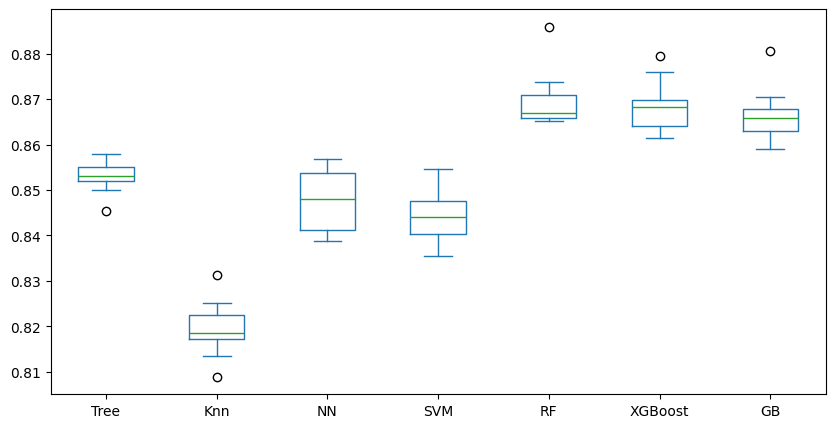

In [89]:
#Resultados de la validación cruzada
comparacion_CV.plot(kind='box', figsize=(10, 5))

In [90]:
import scipy.stats as stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# Obtener los modelos presentes en el DataFrame de comparación
modelos_disponibles = list(comparacion_CV.columns)
print(f"Modelos a evaluar: {modelos_disponibles}")

if len(modelos_disponibles) >= 2:
    # Preparar datos de validación cruzada para cada modelo
    datos_anova = [comparacion_CV[modelo] for modelo in modelos_disponibles]

    # 1. Prueba de ANOVA de una vía
    f_val, p_val = stats.f_oneway(*datos_anova)
    print("\n=== PRUEBA DE ANOVA ===")
    print(f"Estadístico F: {f_val:.4f}")
    print(f"Valor p: {p_val:.4e}")

    if p_val < 0.05:
        print("\nResultado: Existen diferencias estadísticamente significativas entre los modelos (p < 0.05).")

        # Reestructurar datos para Tukey
        df_melt = comparacion_CV[modelos_disponibles].melt(var_name='Modelo', value_name='F1_Macro')

        # 2. Prueba Post-Hoc de Tukey HSD
        tukey = pairwise_tukeyhsd(endog=df_melt['F1_Macro'],
                                  groups=df_melt['Modelo'],
                                  alpha=0.05)
        print("\n=== PRUEBA POST-HOC DE TUKEY HSD ===")
        print(tukey.summary())
    else:
        print("\nResultado: No se encontraron diferencias estadísticamente significativas entre los modelos (p >= 0.05).")
else:
    print("\nError: Se necesitan al menos 2 modelos en 'comparacion_CV' para poder realizar la comparación.")

Modelos a evaluar: ['Tree', 'Knn', 'NN', 'SVM', 'RF', 'XGBoost', 'GB']

=== PRUEBA DE ANOVA ===
Estadístico F: 87.9325
Valor p: 1.0585e-28

Resultado: Existen diferencias estadísticamente significativas entre los modelos (p < 0.05).

=== PRUEBA POST-HOC DE TUKEY HSD ===
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1  group2 meandiff p-adj   lower   upper  reject
-----------------------------------------------------
    GB     Knn  -0.0469    0.0 -0.0551 -0.0387   True
    GB      NN  -0.0187    0.0 -0.0269 -0.0105   True
    GB      RF   0.0033 0.8869 -0.0049  0.0115  False
    GB     SVM  -0.0216    0.0 -0.0298 -0.0134   True
    GB    Tree  -0.0133 0.0001 -0.0215 -0.0051   True
    GB XGBoost   0.0022 0.9823  -0.006  0.0104  False
   Knn      NN   0.0282    0.0    0.02  0.0364   True
   Knn      RF   0.0501    0.0  0.0419  0.0584   True
   Knn     SVM   0.0253    0.0  0.0171  0.0335   True
   Knn    Tree   0.0336    0.0  0.0254  0.0418   True
   Knn XGBoost   0.0491    

In [91]:
#Los 3 mejores modelos según el F1 macro promedio
comparacion_CV.mean().sort_values(ascending=False)

,0
RF,0.869643
XGBoost,0.868580
GB,0.866377
Tree,0.853087
NN,0.847696
SVM,0.844809
Knn,0.819499


GridSearch a los 3 mejores modelos


In [92]:
#Configuración hiperparametrización
from sklearn.model_selection import GridSearchCV
scoring = 'f1_macro' #Se usan los mismos 10 pliegues (cv) de la validación cruzada

#Medida de evaluación de los modelos ajustados
medidas = pd.DataFrame(index=['f1 de la CV'])

GridSearch Random Forest


In [93]:
#Hiperparametrización Random Forest con GridSearch
modelRF = RandomForestClassifier(max_samples=0.9, random_state=42, n_jobs=-1)

# Definir los hiperparametros
n_estimators = [100, 200, 300] #Cantidad de árboles
max_depth = [8, 10, 12, 15, 20] #Niveles de profundidad
min_samples_leaf = [2, 5, 10, 20] #Cantidad de registros por hoja

#Grid
param_grid = dict(n_estimators=n_estimators, max_depth=max_depth, min_samples_leaf=min_samples_leaf)
grid = GridSearchCV(estimator=modelRF, param_grid=param_grid, scoring=scoring, cv=cv, return_train_score=True, refit=True)
grid.fit(X, Y)

#Mejor modelo
modelRF_grid = grid.best_estimator_

# Mejores párametros
print(grid.best_params_)

{'max_depth': 15, 'min_samples_leaf': 5, 'n_estimators': 300}


In [94]:
#Revisar overfitting y underfitting
print("Train CV:", grid.cv_results_["mean_train_score"][grid.best_index_])
print("Test CV:", grid.cv_results_["mean_test_score"][grid.best_index_])

#Medida de evaluación del mejor modelo
medidas['RF GridSearch'] = grid.best_score_
medidas

Train CV: 0.8732134396894691
Test CV: 0.8615816427253277


,RF GridSearch
f1 de la CV,0.861582


gridSearch XGBoost



In [95]:
#Hiperparametrización XGBoost con GridSearch
modelXGB = XGBClassifier(random_state=42, n_jobs=-1)

# Definir los hiperparametros
n_estimators = [200, 300, 400] #Cantidad de árboles
max_depth = [4, 6, 8] #Niveles de profundidad
learning_rate = [0.05, 0.1] #Tasa de aprendizaje

#Grid
param_grid = dict(n_estimators=n_estimators, max_depth=max_depth, learning_rate=learning_rate)
grid = GridSearchCV(estimator=modelXGB, param_grid=param_grid, scoring=scoring, cv=cv, return_train_score=True, refit=True)
grid.fit(X, Y)

#Mejor modelo
modelXGB_grid = grid.best_estimator_

# Mejores párametros
print(grid.best_params_)

{'learning_rate': 0.1, 'max_depth': 8, 'n_estimators': 200}


In [96]:
#Revisar overfitting y underfitting
print("Train CV:", grid.cv_results_["mean_train_score"][grid.best_index_])
print("Test CV:", grid.cv_results_["mean_test_score"][grid.best_index_])

#Medida de evaluación del mejor modelo
medidas['XGBoost GridSearch'] = grid.best_score_
medidas

Train CV: 0.9151952884041537
Test CV: 0.8678893129532304


,RF GridSearch,XGBoost GridSearch
f1 de la CV,0.861582,0.867889


GrindSearch Gradient Boosting


In [97]:
#Hiperparametrización Gradient Boosting con GridSearch
modelGB = GradientBoostingClassifier(random_state=42)

# Definir los hiperparametros
n_estimators = [100, 200, 300] #Cantidad de árboles
max_depth = [3, 4, 5] #Niveles de profundidad
learning_rate = [0.05, 0.1] #Tasa de aprendizaje

#Grid
param_grid = dict(n_estimators=n_estimators, max_depth=max_depth, learning_rate=learning_rate)
grid = GridSearchCV(estimator=modelGB, param_grid=param_grid, scoring=scoring, cv=cv, return_train_score=True, refit=True)
grid.fit(X, Y)

#Mejor modelo
modelGB_grid = grid.best_estimator_

# Mejores párametros
print(grid.best_params_)

{'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 300}


In [98]:
#Revisar overfitting y underfitting
print("Train CV:", grid.cv_results_["mean_train_score"][grid.best_index_])
print("Test CV:", grid.cv_results_["mean_test_score"][grid.best_index_])

#Medida de evaluación del mejor modelo
medidas['GB GridSearch'] = grid.best_score_
medidas

Train CV: 0.8903550768025749
Test CV: 0.864832961360159


,RF GridSearch,XGBoost GridSearch,GB GridSearch
f1 de la CV,0.861582,0.867889,0.864833


In [99]:
!pip install -q scikit-optimize

optimizacion bayesiana


In [100]:
#Optimización bayesiana
from skopt import BayesSearchCV

#Hiperparametrización Random Forest con optimización bayesiana
modelRF = RandomForestClassifier(max_samples=0.9, random_state=42, n_jobs=-1)

# Definir los rangos de los hiperparametros (mínimo, máximo)
n_estimators = (100, 500)
max_depth = (5, 20)
min_samples_leaf = (2, 30)

#Bayesiana (20 intentos)
espacio = dict(n_estimators=n_estimators, max_depth=max_depth, min_samples_leaf=min_samples_leaf)
bayes = BayesSearchCV(estimator=modelRF, search_spaces=espacio, n_iter=20, scoring=scoring, cv=cv, return_train_score=True, refit=True, random_state=42)
bayes.fit(X, Y)

#Mejor modelo
modelRF_bayes = bayes.best_estimator_

# Mejores párametros
print(dict(bayes.best_params_))

{'max_depth': 15, 'min_samples_leaf': 5, 'n_estimators': 500}


In [101]:
#Revisar overfitting y underfitting
print("Train CV:", bayes.cv_results_["mean_train_score"][bayes.best_index_])
print("Test CV:", bayes.cv_results_["mean_test_score"][bayes.best_index_])

#Medida de evaluación del mejor modelo
medidas['RF Bayesiana'] = bayes.best_score_
medidas

Train CV: 0.8731261655831942
Test CV: 0.8608267724154853


,RF GridSearch,XGBoost GridSearch,GB GridSearch,RF Bayesiana
f1 de la CV,0.861582,0.867889,0.864833,0.860827


In [102]:
#Hiperparametrización XGBoost con optimización bayesiana
modelXGB = XGBClassifier(random_state=42, n_jobs=-1)

# Definir los rangos de los hiperparametros (mínimo, máximo)
n_estimators = (100, 600)
max_depth = (3, 7)
learning_rate = (0.01, 0.3, 'log-uniform')

#Bayesiana (20 intentos)
espacio = dict(n_estimators=n_estimators, max_depth=max_depth, learning_rate=learning_rate)
bayes = BayesSearchCV(estimator=modelXGB, search_spaces=espacio, n_iter=20, scoring=scoring, cv=cv, return_train_score=True, refit=True, random_state=42)
bayes.fit(X, Y)

#Mejor modelo
modelXGB_bayes = bayes.best_estimator_

# Mejores párametros
print(dict(bayes.best_params_))

{'learning_rate': 0.06348516039427839, 'max_depth': 7, 'n_estimators': 348}


In [103]:
#Revisar overfitting y underfitting
print("Train CV:", bayes.cv_results_["mean_train_score"][bayes.best_index_])
print("Test CV:", bayes.cv_results_["mean_test_score"][bayes.best_index_])

#Medida de evaluación del mejor modelo
medidas['XGBoost Bayesiana'] = bayes.best_score_
medidas

Train CV: 0.9085915945798021
Test CV: 0.8669888076468496


,RF GridSearch,XGBoost GridSearch,GB GridSearch,RF Bayesiana,XGBoost Bayesiana
f1 de la CV,0.861582,0.867889,0.864833,0.860827,0.866989


In [104]:
#Hiperparametrización Gradient Boosting con optimización bayesiana
modelGB = GradientBoostingClassifier(random_state=42)

# Definir los rangos de los hiperparametros (mínimo, máximo)
n_estimators = (100, 400)
max_depth = (2, 6)
learning_rate = (0.01, 0.3, 'log-uniform')

#Bayesiana (20 intentos)
espacio = dict(n_estimators=n_estimators, max_depth=max_depth, learning_rate=learning_rate)
bayes = BayesSearchCV(estimator=modelGB, search_spaces=espacio, n_iter=20, scoring=scoring, cv=cv, return_train_score=True, refit=True, random_state=42)
bayes.fit(X, Y)

#Mejor modelo
modelGB_bayes = bayes.best_estimator_

# Mejores párametros
print(dict(bayes.best_params_))

{'learning_rate': 0.06348516039427839, 'max_depth': 6, 'n_estimators': 249}


In [105]:
#Revisar overfitting y underfitting
print("Train CV:", bayes.cv_results_["mean_train_score"][bayes.best_index_])
print("Test CV:", bayes.cv_results_["mean_test_score"][bayes.best_index_])

#Medida de evaluación del mejor modelo
medidas['GB Bayesiana'] = bayes.best_score_
medidas

Train CV: 0.9101954815996876
Test CV: 0.8656766273529538


,RF GridSearch,XGBoost GridSearch,GB GridSearch,RF Bayesiana,XGBoost Bayesiana,GB Bayesiana
f1 de la CV,0.861582,0.867889,0.864833,0.860827,0.866989,0.865677


seleccion mejor modelo


In [106]:
medidas.T.sort_values('f1 de la CV', ascending=False)

,f1 de la CV
XGBoost GridSearch,0.867889
XGBoost Bayesiana,0.866989
GB Bayesiana,0.865677
GB GridSearch,0.864833
RF GridSearch,0.861582
RF Bayesiana,0.860827
